# Session 13 lab: Is workforce change creating a capacity problem?

<p class="lead">
Rebuild a company's workforce month by month from employee dates, measure turnover with a fair denominator, follow transfers between teams, keep open roles visible, repair four broken HR calculations, and recommend one investigation an HR partner can defend.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/13_hr_workforce_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *HR partner: "Leadership wants one workforce issue investigated next quarter. Is a team losing people faster than we can replace them, or is recruitment too slow somewhere? Show me the headcount, the exits, the mix of roles and the open requisitions, and tell me what you would look into and what you cannot conclude."*

> **About the data**
>
> `employees.csv`, `department_history.csv` and `recruitment.csv` are **synthetic** teaching data generated by the course for a fictional company. No real person is described, and there are **no names and no demographic or protected attributes**. The observation **cutoff** is 2025-12-31. The exit date is the **first inactive day**.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G4 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I5 |
| **Challenge** | Debugging and a recommendation | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Check keys and date order in interval tables.
2. Decide whether an employee is active on a date, using the first-inactive-day rule.
3. Build a monthly headcount bridge and prove it balances with assertions.
4. Calculate average headcount, monthly turnover and annual turnover correctly.
5. Compare departments fairly, including transfers and small-group flags.
6. Separate tenure of active employees from completed service, and time to fill from open age.
7. Find and fix four common HR calculation bugs.
8. Recommend one capacity or recruitment investigation with its limits.

**Evidence you keep:** a monthly bridge, a turnover trend, a recruitment comparison and a short decision note.

---

## Before you start

- Read the [Session 13 lecture](13_hr_workforce_lecture.md).
- Re-read weighted rates in the [Session 5 lecture](05_metrics_and_kpis_lecture.md).

---

## Guided practice

### G1 (Core): Load the tables and check them

Run the setup cell, then the cell that loads the three tables.

In [1]:
# HR data setup (synthetic). Run this cell first.
# Downloads the course's synthetic workforce data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

HR_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/hr-v1/"
HR_SHA256 = {
    "employees.csv": "7d59a66675d53b7d6de8cce6a4d3369ddd6268e51913e86f30e9560c019342a9",
    "department_history.csv": "12e6524a7838e9d5426c2bef116769ad850d5eaf11e10958a4e4ae13d21dca36",
    "recruitment.csv": "3a6c2046fd5cbb4a07d435f50e3d10e5df160314decd1e651718a5d0bd7fbc05",
}
HR_DATES = {
    "employees.csv": ["hire_date", "exit_date"],
    "department_history.csv": ["effective_from", "effective_to"],
    "recruitment.csv": ["opened_date", "offer_accepted_date", "hire_date"],
}
HR_DIR = os.environ.get("COURSE_HR_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_hr(name):
    """Load one hr-v1 file: 'employees.csv', 'department_history.csv' or 'recruitment.csv'."""
    if HR_DIR:
        with open(os.path.join(HR_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(HR_URL + name).read()
    if hashlib.sha256(data).hexdigest() != HR_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=HR_DATES[name])


print("HR setup complete.")

HR setup complete.


In [2]:
import datetime

import matplotlib.pyplot as plt
import numpy as np

ONE_DAY = datetime.timedelta(days=1)

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

employees = load_hr("employees.csv")
history = load_hr("department_history.csv")
requisitions = load_hr("recruitment.csv")
print("Employees:", len(employees), "| department intervals:", len(history), "| requisitions:", len(requisitions))

Employees: 520 | department intervals: 543 | requisitions: 160


Before counting anything, confirm the **grain** of each table (what one row is) and that the dates are in a sensible order.

In [3]:
checks = {
    "employees: employee_id is unique": employees["employee_id"].is_unique,
    "history: (employee_id, effective_from) is unique": not history.duplicated(["employee_id", "effective_from"]).any(),
    "requisitions: requisition_id is unique": requisitions["requisition_id"].is_unique,
    "history employees all exist in employees": history["employee_id"].isin(employees["employee_id"]).all(),
    "exit after hire, when there is an exit": (employees["exit_date"].isna()
                                               | (employees["exit_date"] > employees["hire_date"])).all(),
    "nothing dated after the cutoff": (employees[["hire_date", "exit_date"]].max() <= CUTOFF).all(),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

print()
print("Employees hired before 2025:", (employees["hire_date"] < "2025-01-01").sum())
print("Employees with an exit date:", employees["exit_date"].notna().sum())

PASS - employees: employee_id is unique
PASS - history: (employee_id, effective_from) is unique
PASS - requisitions: requisition_id is unique
PASS - history employees all exist in employees
PASS - exit after hire, when there is an exit
PASS - nothing dated after the cutoff

Employees hired before 2025: 379
Employees with an exit date: 131


> **Why the pre-2025 hires matter**
>
> Most of the people working on 1 January 2025 were hired years earlier. Without them, the opening headcount would be far too low and every turnover rate far too high.

### G2 (Core): Who is active on a date?

An employee is active on day *d* when *hire_date ≤ d* and *(exit_date is blank or exit_date > d)*. The exit date itself is the **first day they are gone**.

In [4]:
def is_active(table, day, start="hire_date", end="exit_date"):
    """True for each row whose interval [start, end) contains `day`. A blank end means still open."""
    day = pd.Timestamp(day)
    return (table[start] <= day) & (table[end].isna() | (table[end] > day))


def active_on(table, day, start="hire_date", end="exit_date"):
    """How many rows are active on `day`."""
    return int(is_active(table, day, start, end).sum())

> **Your turn:** change the code in the next cell and run it again.

In [5]:
# 1. Run the cell. Which of the five made-up employees are active on 2025-03-31?
# 2. Change day to "2025-04-01". Who drops out, and why?
# 3. Change day to "2025-03-01". Is C active? Is B? Explain using the rule above.
day = "2025-03-31"

fixture = pd.DataFrame({
    "employee_id": ["A", "B", "C", "D", "E"],
    "hire_date": pd.to_datetime(["2024-06-10", "2025-03-01", "2023-02-13", "2022-09-05", "2021-11-22"]),
    "exit_date": pd.to_datetime([None, None, "2025-03-01", "2025-03-17", "2025-04-01"]),
})
fixture.assign(active=is_active(fixture, day))

,employee_id,hire_date,exit_date,active
0,A,2024-06-10,NaT,True
1,B,2025-03-01,NaT,True
2,C,2023-02-13,2025-03-01,False
3,D,2022-09-05,2025-03-17,False
4,E,2021-11-22,2025-04-01,True


### G3 (Core): The monthly company bridge

For each month: **opening** = active on the last day of the previous month; **hires** and **exits** = events dated in the month; **closing** = active on the last day of the month. Then *closing = opening + hires − exits*. The `assert` lines stop the notebook if the bridge ever fails.

In [6]:
def month_bridge(table, month_start):
    """Opening, hires, exits and closing for the month that starts on `month_start`."""
    start = pd.Timestamp(month_start)
    end = start + pd.offsets.MonthEnd(0)                       # last day of the month
    return {
        "opening": active_on(table, start - ONE_DAY),  # active on the last day of the previous month
        "hires": int(table["hire_date"].between(start, end).sum()),
        "exits": int(table["exit_date"].between(start, end).sum()),
        "closing": active_on(table, end),                     # active on the last day of this month
    }


months = pd.date_range("2025-01-01", "2025-12-01", freq="MS")

bridge = pd.DataFrame([month_bridge(employees, m) for m in months], index=months.strftime("%Y-%m"))
bridge.index.name = "month"

# Two checks that must always pass.
assert (bridge["closing"] == bridge["opening"] + bridge["hires"] - bridge["exits"]).all(), "bridge does not balance"
assert (bridge["opening"].iloc[1:].to_numpy() == bridge["closing"].iloc[:-1].to_numpy()).all(), "months do not chain"
print("Bridge balances in all 12 months, and each closing equals the next opening.")
bridge

Bridge balances in all 12 months, and each closing equals the next opening.


,opening,hires,exits,closing
month,,,,
2025-01,379,1,9,371
2025-02,371,6,9,368
2025-03,368,6,7,367
2025-04,367,8,2,373
2025-05,373,15,10,378
2025-06,378,36,8,406
2025-07,406,18,6,418
2025-08,418,12,18,412
2025-09,412,16,19,409


> **Your turn:** change the code in the next cell and run it again.

In [7]:
# 1. Run the cell. It lists who joined and who left in the chosen month.
# 2. Change month to "2025-06". Why is this month unusual?
# 3. Find an exit dated on the 1st of a month (try "2025-07"). Is that person in the month's opening? Why?
month = "2025-11"

start = pd.Timestamp(month + "-01")
end = start + pd.offsets.MonthEnd(0)
joined = employees[employees["hire_date"].between(start, end)]
left = employees[employees["exit_date"].between(start, end)]
print(bridge.loc[month].to_dict())
print(f"Hires listed: {len(joined)} | exits listed: {len(left)}")
left.sort_values("exit_date").head(10)

{'opening': 404, 'hires': 9, 'exits': 21, 'closing': 392}
Hires listed: 9 | exits listed: 21


,employee_id,hire_date,exit_date,job_family
157,E0158,2024-10-25,2025-11-01,Warehouse
179,E0180,2024-09-07,2025-11-02,Warehouse
479,E0480,2025-08-03,2025-11-03,Warehouse
500,E0501,2025-10-15,2025-11-04,Warehouse
111,E0112,2024-05-16,2025-11-06,Warehouse
502,E0503,2025-10-19,2025-11-11,Sales
75,E0076,2017-05-12,2025-11-15,Marketing
115,E0116,2020-09-25,2025-11-17,Warehouse
249,E0250,2022-11-14,2025-11-17,Warehouse
447,E0448,2025-06-23,2025-11-18,Warehouse


### G4 (Core): Average headcount and turnover

Monthly average headcount ≈ (opening + closing) ÷ 2. Monthly turnover = exits ÷ that average. **Annual turnover = exits in the year ÷ mean of the 12 monthly averages.**

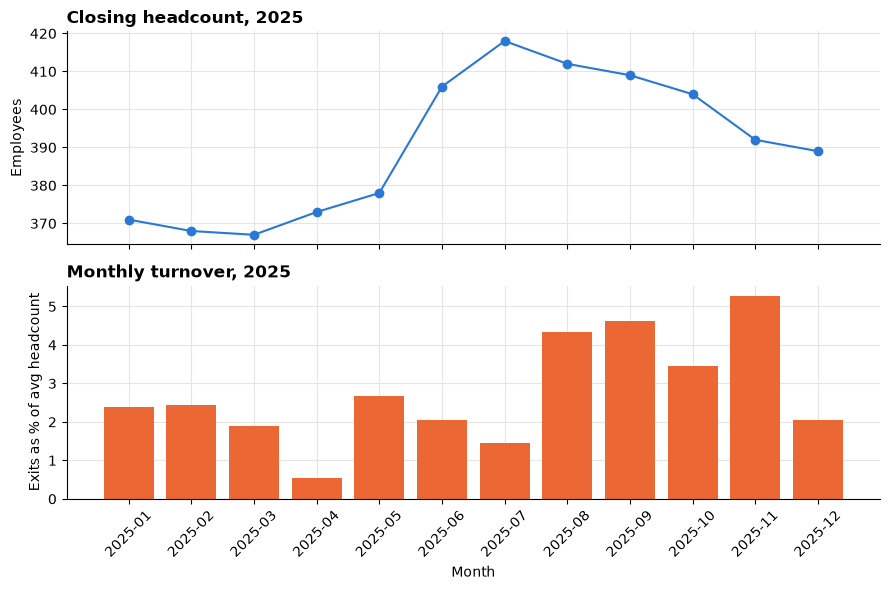

Annual exits: 131 | annual turnover: 33.6%
Wrong, ÷ December closing headcount: 33.7%
Wrong, mean of monthly rates:        2.8%  (a monthly figure)


In [8]:
bridge["avg_headcount"] = (bridge["opening"] + bridge["closing"]) / 2
bridge["turnover"] = (bridge["exits"] / bridge["avg_headcount"]).where(bridge["avg_headcount"] > 0)
annual_exits = bridge["exits"].sum()
annual_turnover = annual_exits / bridge["avg_headcount"].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
x = np.arange(12)
ax1.plot(x, bridge["closing"], marker="o")
ax1.set_title("Closing headcount, 2025")
ax1.set_ylabel("Employees")
ax2.bar(x, bridge["turnover"] * 100, color="#eb6834")
ax2.set_title("Monthly turnover, 2025")
ax2.set_ylabel("Exits as % of avg headcount")
ax2.set_xticks(x, bridge.index, rotation=45)
ax2.set_xlabel("Month")
fig.tight_layout()
plt.show()

print(f"Annual exits: {annual_exits} | annual turnover: {annual_turnover:.1%}")
print(f"Wrong, ÷ December closing headcount: {annual_exits / bridge['closing'].iloc[-1]:.1%}")
print(f"Wrong, mean of monthly rates:        {bridge['turnover'].mean():.1%}  (a monthly figure)")

Write one sentence in your evidence log: the annual turnover, with the words "exits", "average headcount" and "2025".

---

## Independent tasks

### I1 (Core): Department turnover, two denominators

The functions below build a monthly bridge for each department from its intervals. Transfers have their own columns (more in I2). Run them, then compare the **correct** denominator (mean of monthly average headcounts) with the **current** headcount (December closing).

In [9]:
def add_interval_flags(history):
    """Mark each employee's first and last department interval."""
    h = history.sort_values(["employee_id", "effective_from"]).copy()
    h["first_interval"] = ~h.duplicated("employee_id", keep="first")
    h["last_interval"] = ~h.duplicated("employee_id", keep="last")
    return h


def department_month(h, department, month_start):
    """Department bridge for one month: a transfer is neither a hire nor an exit."""
    d = h[h["department"] == department]
    start = pd.Timestamp(month_start)
    end = start + pd.offsets.MonthEnd(0)
    starts = d["effective_from"].between(start, end)
    ends = d["effective_to"].between(start, end)
    return {
        "opening": active_on(d, start - ONE_DAY, "effective_from", "effective_to"),
        "hires": int((starts & d["first_interval"]).sum()),
        "transfers_in": int((starts & ~d["first_interval"]).sum()),
        "exits": int((ends & d["last_interval"]).sum()),
        "transfers_out": int((ends & ~d["last_interval"]).sum()),
        "closing": active_on(d, end, "effective_from", "effective_to"),
    }


def department_bridge(h, department):
    """Monthly 2025 bridge for one department, checked to balance."""
    b = pd.DataFrame([department_month(h, department, m) for m in months], index=months.strftime("%Y-%m"))
    b.index.name = "month"
    expected = b["opening"] + b["hires"] + b["transfers_in"] - b["exits"] - b["transfers_out"]
    assert (b["closing"] == expected).all(), f"{department} bridge does not balance"
    return b


history = add_interval_flags(history)
departments = sorted(history["department"].unique())
dept_bridges = {d: department_bridge(history, d) for d in departments}
print("Built and checked bridges for:", ", ".join(departments))

Built and checked bridges for: Finance and Admin, Marketing, Operations, People, Sales, Technology


> **Your turn:** change the code in the next cell and run it again.

In [10]:
# 1. Run the cell. For which departments does "÷ current" overstate turnover, and for which does it understate it?
# 2. Link each gap to the department's headcount path: did it grow or shrink during 2025?
# 3. Change MIN_COUNT to 10. Which departments are now flagged? Should a flagged department be ranked?
MIN_COUNT = 5

rows = {}
for d, b in dept_bridges.items():
    avg = ((b["opening"] + b["closing"]) / 2).mean()
    rows[d] = {"Jan opening": b["opening"].iloc[0], "Dec closing": b["closing"].iloc[-1],
               "exits": b["exits"].sum(), "avg headcount": round(avg, 1),
               "correct": b["exits"].sum() / avg, "÷ current": b["exits"].sum() / b["closing"].iloc[-1]}
dept = pd.DataFrame(rows).T.astype({"Jan opening": int, "Dec closing": int, "exits": int})
dept["flag"] = np.where(dept["exits"] < MIN_COUNT, "small: do not rank", "")
dept.sort_values("correct", ascending=False).assign(
    correct=lambda t: t["correct"].map("{:.1%}".format),
    **{"÷ current": lambda t: t["÷ current"].map("{:.1%}".format)},
)

,Jan opening,Dec closing,exits,avg headcount,correct,÷ current,flag
Operations,162,151,89,165.40,53.8%,58.9%,
People,12,18,4,13.90,28.7%,22.2%,small: do not rank
Sales,70,70,15,69.20,21.7%,21.4%,
Marketing,30,28,6,30.90,19.4%,21.4%,
Finance and Admin,25,23,4,23.80,16.8%,17.4%,small: do not rank
Technology,80,99,13,86.90,15.0%,13.1%,


> **Hint**
>
> Dividing by December's headcount asks "how many people left, compared with who is here **now**?" The people exposed to leaving during the year were the people here **during** the year.

### I2 (Core): A department bridge with transfers

A transfer moves a person between departments: it is a **transfer out** for one and a **transfer in** for the other, but **not** a hire or an exit.

> **Your turn:** change the code in the next cell and run it again.

In [11]:
# 1. Run the cell. Does the bridge balance every month? How many people moved in and out during 2025?
# 2. Change department to "People", then "Sales". Which department grew mostly through transfers?
# 3. Explain in one sentence why the transfers columns are needed for a department but not for the company.
department = "Technology"

b = dept_bridges[department]
print(f"{department}: hires {b['hires'].sum()}, transfers in {b['transfers_in'].sum()}, "
      f"exits {b['exits'].sum()}, transfers out {b['transfers_out'].sum()}")
b

Technology: hires 34, transfers in 4, exits 13, transfers out 6


,opening,hires,transfers_in,exits,transfers_out,closing
month,,,,,,
2025-01,80,1,0,0,0,81
2025-02,81,0,0,1,1,79
2025-03,79,0,0,1,0,78
2025-04,78,3,0,0,1,80
2025-05,80,6,0,2,3,81
2025-06,81,6,0,1,0,86
2025-07,86,2,1,1,0,88
2025-08,88,5,1,3,0,91
2025-09,91,6,0,1,1,95


Now check that the department bridges and the company bridge tell the same story.

In [12]:
flows = ["opening", "hires", "transfers_in", "exits", "transfers_out", "closing"]
total = sum(b[flows] for b in dept_bridges.values())
print("Transfers cancel across departments:", (total["transfers_in"] == total["transfers_out"]).all())
for col in ["opening", "hires", "exits", "closing"]:
    print(f"Department {col} add up to the company:", (total[col] == bridge[col]).all())

Transfers cancel across departments: True
Department opening add up to the company: True
Department hires add up to the company: True
Department exits add up to the company: True
Department closing add up to the company: True


### I3 (Core): Tenure of the active workforce

**Tenure at the cutoff** covers employees active on 2025-12-31 only: cutoff − hire date. Leavers have **completed service** instead (exit − hire), which you look at in step 3.

> **Your turn:** change the code in the next cell and run it again.

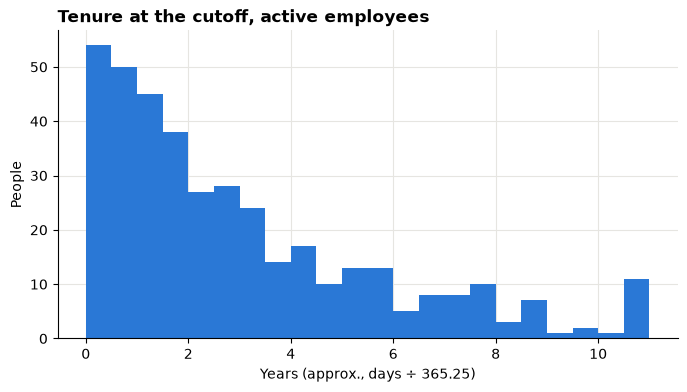

,count,median,mean
job_family,,,
Corporate,35,3.30,4.00
Engineering,102,1.90,2.70
Marketing,26,2.60,3.20
Sales,71,2.40,3.40
Warehouse,155,1.60,2.70


In [13]:
# 1. Run the cell. Describe the shape of the tenure distribution. Is the mean or the median a better summary?
# 2. Change group_by to "department". Which group has the newest workforce? Is any group too small to compare?
# 3. Change who to "leavers". The cell then shows completed service. Why must the two never be mixed?
group_by = "job_family"
who = "active"

if who == "active":
    people = employees[is_active(employees, CUTOFF)].copy()
    people["days"] = (CUTOFF - people["hire_date"]).dt.days
    label = "Tenure at the cutoff, active employees"
else:
    people = employees[employees["exit_date"].notna()].copy()
    people["days"] = (people["exit_date"] - people["hire_date"]).dt.days
    label = "Completed service, leavers"
people["years"] = people["days"] / 365.25
if group_by == "department":
    last = history[history["last_interval"]].set_index("employee_id")["department"]
    people["department"] = people["employee_id"].map(last)

ax = plt.gca()
ax.hist(people["years"], bins=np.arange(0, 11.5, 0.5))
ax.set_title(label)
ax.set_xlabel("Years (approx., days ÷ 365.25)")
ax.set_ylabel("People")
plt.show()

people.groupby(group_by)["years"].agg(["count", "median", "mean"]).round(1)

### I4 (Core): Time to fill, with open roles kept visible

**Time to fill** = offer accepted date − opened date, for roles with an accepted offer. Roles still **open** at the cutoff get an **open age** = cutoff − opened date, shown separately. Canceled roles are counted, not timed.

In [14]:
req = requisitions.copy()
req["days_to_fill"] = (req["offer_accepted_date"] - req["opened_date"]).dt.days
req["open_age_days"] = (CUTOFF - req["opened_date"]).dt.days.where(req["status"] == "open")
print(req["status"].value_counts().to_string())

status
filled      143
canceled      8
open          5
accepted      4


> **Your turn:** change the code in the next cell and run it again.

In [15]:
# 1. Run the cell. Which group is slowest to fill roles? Which has roles open the longest?
# 2. Change group_by to "job_family". Does the picture change?
# 3. Look at the "accepted" column. Which medians rest on so few roles that you would not compare them?
group_by = "department"

summary = req.groupby(group_by).agg(
    accepted=("days_to_fill", "count"),
    median_days_to_fill=("days_to_fill", "median"),
    open_roles=("open_age_days", "count"),
    oldest_open_age=("open_age_days", "max"),
    canceled=("status", lambda s: int((s == "canceled").sum())),
)
display(summary)
print("Roles still open at the cutoff:")
req.loc[req["status"] == "open", ["requisition_id", group_by, "opened_date", "open_age_days"]]

,accepted,median_days_to_fill,open_roles,oldest_open_age,canceled
department,,,,,
Finance and Admin,2,40.00,1,6.00,1
Marketing,1,23.00,2,43.00,0
Operations,88,18.00,0,NaN,3
People,4,39.00,0,NaN,0
Sales,17,41.00,0,NaN,1
Technology,35,54.00,2,75.00,3


Roles still open at the cutoff:


,requisition_id,department,opened_date,open_age_days
150,R0152,Technology,2025-10-17,75.00
153,R0155,Marketing,2025-11-18,43.00
157,R0158,Marketing,2025-12-09,22.00
158,R0159,Technology,2025-12-12,19.00
159,R0160,Finance and Admin,2025-12-25,6.00


> **Open age is a lower bound**
>
> A role open for 75 days will take **at least** 75 days to fill. Leaving it out of a median, or recording it as 0, hides the slowest cases.

### I5 (Stretch): Do new hires stay?

A **cohort** is a group that starts together. Here a cohort is the employees hired in the same quarter of 2025. For a fair comparison, every cohort must be followed for the **same** length of time, so we ask: what share were still employed **90 days** after their hire date? Only hires with at least 90 days of follow-up before the cutoff are included.

> **Your turn:** change the code in the next cell and run it again.

In [16]:
# 1. Run the cell. Which hire quarter kept the smallest share of its starters for 90 days?
# 2. Change department to "All". Is the pattern specific to one department?
# 3. Change follow_up_days to 180. Why does one cohort shrink to only a few starters? Can you still compare it fairly?
department = "Operations"
follow_up_days = 90

first_dept = history[history["first_interval"]].set_index("employee_id")["department"]
hires = employees[employees["hire_date"] >= "2025-01-01"].copy()
hires["department"] = hires["employee_id"].map(first_dept)
if department != "All":
    hires = hires[hires["department"] == department]
hires["check_day"] = hires["hire_date"] + datetime.timedelta(days=follow_up_days)
hires = hires[hires["check_day"] <= CUTOFF].copy()      # only hires we can follow long enough
hires["stayed"] = hires["exit_date"].isna() | (hires["exit_date"] > hires["check_day"])
hires["hire_quarter"] = hires["hire_date"].dt.to_period("Q").astype(str)

hires.groupby("hire_quarter").agg(starters=("stayed", "size"), stayed=("stayed", "sum"),
                                  share_stayed=("stayed", "mean")).round(2)

,starters,stayed,share_stayed
hire_quarter,,,
2025Q1,7,7,1.00
2025Q2,39,27,0.69
2025Q3,28,21,0.75


> **Why not look at 2023 or 2024 hires?**
>
> This extract contains only people who were still employed on 1 January 2025 or were hired later. Anyone hired in 2023 who left in 2024 is **missing**, so earlier cohorts would look perfectly loyal. That is **survivorship bias**: you can only study the cohorts whose leavers are in the data.

---

## Challenge

### C1 (Challenge): Four broken HR calculations

Each cell below contains **one** bug that the lecture warned about, plus a check. For each one:

1. Run the cell as it is and write down the result (**before**).
2. Fix the line marked `# FIX ME`, run again and write down the result (**after**).
3. Write one sentence saying what the bug would have made a manager believe.

**Bug 1: turnover divided by current headcount.**

> **Your turn:** change the code in the next cell and run it again.

In [17]:
def department_turnover(b):
    """Annual turnover for one department bridge."""
    return b["exits"].sum() / b["closing"].iloc[-1]          # FIX ME


result = pd.Series({d: department_turnover(b) for d, b in dept_bridges.items()})
reference = pd.Series({d: b["exits"].sum() / ((b["opening"] + b["closing"]) / 2).mean()
                       for d, b in dept_bridges.items()})
print("CHECK:", "PASS" if np.allclose(result, reference) else "FAIL - not the contract's denominator")
result.map("{:.1%}".format).to_frame("turnover")

CHECK: FAIL - not the contract's denominator


,turnover
Finance and Admin,17.4%
Marketing,21.4%
Operations,58.9%
People,22.2%
Sales,21.4%
Technology,13.1%


**Bug 2: the exit date treated as the last working day.**

> **Your turn:** change the code in the next cell and run it again.

In [18]:
def active_count(table, day):
    """How many employees are active on `day`."""
    day = pd.Timestamp(day)
    return int(((table["hire_date"] <= day)
                & (table["exit_date"].isna() | (table["exit_date"] >= day))).sum())   # FIX ME


rows = []
for m in months:
    start, end = m, m + pd.offsets.MonthEnd(0)
    rows.append({"month": m.strftime("%Y-%m"),
                 "opening": active_count(employees, start - ONE_DAY),
                 "hires": int(employees["hire_date"].between(start, end).sum()),
                 "exits": int(employees["exit_date"].between(start, end).sum()),
                 "closing": active_count(employees, end)})
test = pd.DataFrame(rows).set_index("month")
broken = test.index[test["closing"] != test["opening"] + test["hires"] - test["exits"]]
print("CHECK:", "PASS" if len(broken) == 0 else f"FAIL - bridge does not balance in {list(broken)}")

CHECK: FAIL - bridge does not balance in ['2025-02', '2025-03', '2025-06', '2025-07', '2025-08', '2025-10']


> **Hint**
>
> Look at the exits in the failing months. On which day of the month are they dated? Is that person active on that day?

**Bug 3: open requisitions recorded as 0 days.**

> **Your turn:** change the code in the next cell and run it again.

In [19]:
timed = requisitions[requisitions["status"] != "canceled"].copy()
timed["days_to_fill"] = (timed["offer_accepted_date"] - timed["opened_date"]).dt.days.fillna(0)   # FIX ME

medians = timed.groupby("department")["days_to_fill"].median()
zero_days = int((timed["days_to_fill"] == 0).sum())
print("CHECK:", "PASS" if zero_days == 0 else f"FAIL - {zero_days} roles recorded as 0 days to fill")
medians.to_frame("median days to fill")

CHECK: FAIL - 5 roles recorded as 0 days to fill


,median days to fill
department,
Finance and Admin,18.00
Marketing,0.00
Operations,18.00
People,39.00
Sales,41.00
Technology,53.00


> **Hint**
>
> After the fix, the open roles must not vanish either. Where do they appear in your answer? (Look back at I4.)

**Bug 4: transfers counted as hires and exits.**

> **Your turn:** change the code in the next cell and run it again.

In [20]:
in_2025 = history["effective_from"].between("2025-01-01", CUTOFF)
out_2025 = history["effective_to"].between("2025-01-01", CUTOFF)
dept_hires = history[in_2025].groupby("department").size()            # FIX ME
dept_exits = history[out_2025].groupby("department").size()           # FIX ME

company_hires = int(employees["hire_date"].between("2025-01-01", CUTOFF).sum())
company_exits = int(employees["exit_date"].between("2025-01-01", CUTOFF).sum())
ok = dept_hires.sum() == company_hires and dept_exits.sum() == company_exits
print(f"Department hires add to {dept_hires.sum()} (company {company_hires}); "
      f"department exits add to {dept_exits.sum()} (company {company_exits})")
print("CHECK:", "PASS" if ok else "FAIL - department hires or exits do not add up to the company")

Department hires add to 164 (company 141); department exits add to 154 (company 131)
CHECK: FAIL - department hires or exits do not add up to the company


> **Hint**
>
> An interval that is **not** an employee's first one starts with a transfer in. An interval that is **not** the last one ends with a transfer out. The `first_interval` and `last_interval` columns already mark them.

### C2 (Challenge): Recommend one investigation

The panel below puts the evidence side by side. Choose a `focus` department; it is highlighted in orange.

> **Your turn:** change the code in the next cell and run it again.

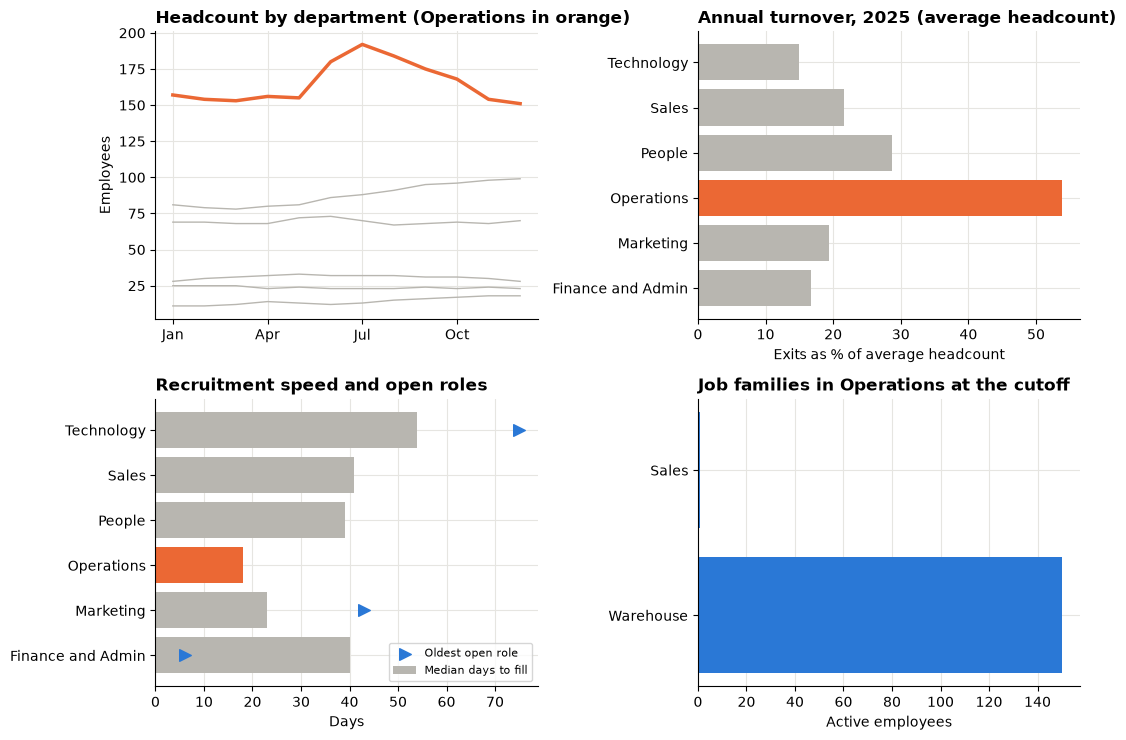

In [21]:
# 1. Run the cell with focus = "Operations", then try "Technology".
# 2. For each, note headcount path, exits, turnover, job-family mix and open roles.
# 3. Decide which ONE investigation you would recommend, then write the note below.
focus = "Operations"

colours = ["#eb6834" if d == focus else "#b8b6b0" for d in departments]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

ax = axes[0, 0]
for d in departments:
    ax.plot(range(12), dept_bridges[d]["closing"], color="#eb6834" if d == focus else "#b8b6b0",
            linewidth=2.5 if d == focus else 1)
ax.set_title(f"Headcount by department ({focus} in orange)")
ax.set_xticks(range(0, 12, 3), ["Jan", "Apr", "Jul", "Oct"])
ax.set_ylabel("Employees")

ax = axes[0, 1]
correct = pd.Series({d: dept.loc[d, "correct"] for d in departments}) * 100
ax.barh(departments, correct, color=colours)
ax.set_title("Annual turnover, 2025 (average headcount)")
ax.set_xlabel("Exits as % of average headcount")

ax = axes[1, 0]
fill = req.groupby("department")["days_to_fill"].median().reindex(departments)
ax.barh(departments, fill, color=colours, label="Median days to fill")
open_age = req.groupby("department")["open_age_days"].max().reindex(departments)
ax.scatter(open_age, departments, marker=">", s=70, color="#2a78d6", label="Oldest open role", zorder=3)
ax.set_title("Recruitment speed and open roles")
ax.set_xlabel("Days")
ax.legend(fontsize=8)

ax = axes[1, 1]
fam = employees.set_index("employee_id")["job_family"]
in_focus = history[(history["department"] == focus) & is_active(history, CUTOFF, "effective_from", "effective_to")]
mix = in_focus["employee_id"].map(fam).value_counts()
ax.barh(mix.index, mix.values, color="#2a78d6")
ax.set_title(f"Job families in {focus} at the cutoff")
ax.set_xlabel("Active employees")

fig.tight_layout()
plt.show()

Write a **decision note** of about 150 words in your evidence log:

1. **Recommendation**: the one capacity or recruitment issue you would investigate, and in which team.
2. **Evidence**: headcount at the start, peak and end of 2025; exits and annual turnover on average headcount; job-family mix; open roles and their ages.
3. **Alternative explanations**: at least two (for example, planned seasonal contracts, a fall in demand, a recording change).
4. **Extra evidence you would ask for**: at least two items that this data does not contain.
5. **Limits**: small groups you did not rank, and what this descriptive data cannot show.

> **Do not write**
>
> "Operations managers are driving people out." "Technology recruiters are slow." "People leave because of the pay." Descriptive counts cannot show causes, the quality of anyone's work, or discrimination.

---

## Validation checklist

- [ ] Keys are unique and every exit is after its hire.
- [ ] Employees hired before 2025 are included in the opening headcount.
- [ ] The exit date is treated as the **first inactive day** (exit > d for "active").
- [ ] The company bridge balances and chains every month (asserted, not eyeballed).
- [ ] Annual turnover = annual exits ÷ mean of 12 monthly average headcounts.
- [ ] Department bridges include transfers; department totals add up to the company.
- [ ] Tenure covers active employees only; completed service is reported separately.
- [ ] Open roles appear with their open age; none is recorded as 0 days; canceled roles are counted.
- [ ] Groups with fewer than about 5 people or events are flagged or combined, not ranked.

---

## Exit ticket

1. An employee's last working day is 30 June. What is their exit date, and are they in June's closing headcount?
2. Why is dividing a year's exits by today's headcount misleading for a team that grew during the year?
3. Why is the mean of 12 monthly turnover rates not the annual turnover?
4. A person moves from Sales to Marketing. What happens to the company bridge and to each department's bridge?
5. Why must an open role never be recorded as 0 days to fill?

---

## Evidence to keep

- [ ] The monthly company bridge with its assertions (G3) and the turnover figures (G4)
- [ ] The department turnover table with both denominators and small-group flags (I1)
- [ ] The recruitment comparison with open roles and their ages (I4)
- [ ] Your before/after notes for the four bugs (C1)
- [ ] Your decision note (C2)